_______________
# HR Workforce Analysis Project
_______________

### 1. Project Overview
The objective of this project is to analyze workforce data using MySQL and Python to understand employee distribution, salary patterns, attendance, leave records, recruitment, and other HR-related metrics.

### 2. Tools and Technologies
- MySQL
- Python
- Jupyter Notebook
- MySQL Connector for Python
- Pandas (for data analysis)
- Matplotlib

### 3. Establishing MySQL Connection and Connecting to the HR Workforce Database

In [1]:
import mysql.connector

In [2]:
conn = mysql.connector.connect(host="localhost", user="root", password="Priyanshi@4455", database="hr_workforce_analysis")
print("connection successful")

connection successful


### 4. Creating a Cursor and Selecting the Database

In [3]:
cursor = conn.cursor()
cursor.execute("use hr_workforce_analysis")

### 5. Listing Available Database Tables

In [4]:
cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table[0])

attendance
employee_master
leave
recruitment_summary


### 6. Exploring Table Structures

In [5]:
cursor.execute("SHOW TABLES")
tables = cursor.fetchall()

for table in tables:
    print(f"\nTable: {table[0]}")
    cursor.execute(f"DESCRIBE `{table[0]}`")

    for column in cursor.fetchall():
        print(column)


Table: attendance
('ï»¿Employee_ID', 'int', 'YES', '', None, '')
('Month', 'text', 'YES', '', None, '')
('Working_Days', 'int', 'YES', '', None, '')
('Present_Days', 'int', 'YES', '', None, '')
('Absent_Days', 'int', 'YES', '', None, '')
('Late_Days', 'int', 'YES', '', None, '')
('Attendance_Percentage', 'double', 'YES', '', None, '')

Table: employee_master
('Employee_ID', 'int', 'YES', '', None, '')
('Employee_Name', 'text', 'YES', '', None, '')
('Gender', 'text', 'YES', '', None, '')
('Age', 'int', 'YES', '', None, '')
('Department', 'text', 'YES', '', None, '')
('Position', 'text', 'YES', '', None, '')
('Salary', 'int', 'YES', '', None, '')
('Hire_Date', 'text', 'YES', '', None, '')
('Years_of_Service', 'double', 'YES', '', None, '')
('Recruitment_Source', 'text', 'YES', '', None, '')
('Performance_Score', 'double', 'YES', '', None, '')
('Attendance_Percentage', 'double', 'YES', '', None, '')
('Absence_Days', 'int', 'YES', '', None, '')
('Leave_Days', 'int', 'YES', '', None, '')
(


**Table structures identified:**

#### 7.1 Attendance Table
- Employee_ID
- Month
- Working_Days
- Present_Days
- Absent_Days
- Late_Days
- Attendance_Percentage

#### 7.2 Employee Master Table
- Employee_ID
- Employee_Name
- Gender
- Age
- Department
- Position
- Salary
- Hire_Date
- Years_of_Service
- Recruitment_Source
- Performance_Score
- Attendance_Percentage
- Absence_Days
- Leave_Days
- Employment_Status
- Termination_Date
- Location
- Status

#### 7.3 Leave Table
- Leave_ID
- Employee_ID
- Leave_Date
- Leave_Type
- Leave_Days
- Status

#### 7.4 Recruitment Summary Table
- Recruitment_Source
- Total_Hires
- Average_Performance
- Average_Salary

### 8. SQL Analysis Plan

#### 8.1. Total employee count

In [6]:
cursor.execute("SELECT COUNT(*) FROM employee_master")
total_employees = cursor.fetchone()[0]

print("Total Employees:", total_employees)

Total Employees: 300


#### 8.2. Department-wise employee distribution

In [7]:
cursor.execute("""
    SELECT
        Department,
        COUNT(*) AS Total_Employees
    FROM employee_master
    GROUP BY Department
    ORDER BY Total_Employees DESC
""")

results = cursor.fetchall()

print("Department-wise Employee Count")
print("-" * 40)

for row in results:
    print(f"Department: {row[0]} | Employees: {row[1]}")

Department-wise Employee Count
----------------------------------------
Department: IT | Employees: 54
Department: Sales | Employees: 48
Department: HR | Employees: 44
Department: Finance | Employees: 43
Department: Customer Support | Employees: 40
Department: Marketing | Employees: 38
Department: Operations | Employees: 33


#### 8.3. Salary statistics

In [8]:
cursor.execute("""
    SELECT
        COUNT(*) AS Total_Employees,
        ROUND(AVG(Salary), 2) AS Average_Salary,
        MIN(Salary) AS Minimum_Salary,
        MAX(Salary) AS Maximum_Salary
    FROM employee_master
""")

result = cursor.fetchone()

print("Employee Salary Analysis")
print("-" * 35)
print("Total Employees:", result[0])
print("Average Salary:", result[1])
print("Minimum Salary:", result[2])
print("Maximum Salary:", result[3])

Employee Salary Analysis
-----------------------------------
Total Employees: 300
Average Salary: 45356.67
Minimum Salary: 18000
Maximum Salary: 77000


#### 8.4. Gender distribution

In [9]:
cursor.execute("""
    SELECT
        Gender,
        COUNT(*) AS Total_Employees
    FROM employee_master
    GROUP BY Gender
    ORDER BY Total_Employees DESC
""")

results = cursor.fetchall()

print("Gender-wise Workforce Distribution")
print("-" * 40)

for row in results:
    print(f"Gender: {row[0]} | Employees: {row[1]}")

Gender-wise Workforce Distribution
----------------------------------------
Gender: Male | Employees: 162
Gender: Female | Employees: 138


#### 8.5. Employee Attendance Analysis

In [10]:
cursor.execute("""
    SELECT
        COUNT(*) AS Total_Records,
        SUM(Working_Days) AS Total_Working_Days,
        SUM(Present_Days) AS Total_Present_Days,
        SUM(Absent_Days) AS Total_Absent_Days,
        SUM(Late_Days) AS Total_Late_Days,
        ROUND(AVG(Attendance_Percentage), 2) AS Average_Attendance
    FROM attendance
""")

result = cursor.fetchone()

print("Overall Attendance Analysis")
print("-" * 40)
print("Total Attendance Records:", result[0])
print("Total Working Days:", result[1])
print("Total Present Days:", result[2])
print("Total Absent Days:", result[3])
print("Total Late Days:", result[4])
print("Average Attendance (%):", result[5])

Overall Attendance Analysis
----------------------------------------
Total Attendance Records: 3600
Total Working Days: 72025
Total Present Days: 55870
Total Absent Days: 16155
Total Late Days: 9674
Average Attendance (%): 77.47


#### 8.6. Monthly Attendance Trend Analysis

In [11]:
cursor.execute("""
    SELECT
        Month,
        SUM(Present_Days) AS Total_Present_Days,
        SUM(Absent_Days) AS Total_Absent_Days,
        SUM(Late_Days) AS Total_Late_Days,
        ROUND(AVG(Attendance_Percentage), 2) AS Average_Attendance
    FROM attendance
    GROUP BY Month
    ORDER BY Month
""")

results = cursor.fetchall()

print("Monthly Attendance Trend")
print("-" * 65)
print(
    f"{'Month':<15}"
    f"{'Present':<12}"
    f"{'Absent':<12}"
    f"{'Late':<10}"
    f"{'Avg Attendance %':<15}"
)

for row in results:
    print(
        f"{str(row[0]):<15}"
        f"{str(row[1]):<12}"
        f"{str(row[2]):<12}"
        f"{str(row[3]):<10}"
        f"{str(row[4]):<15}"
    )

Monthly Attendance Trend
-----------------------------------------------------------------
Month          Present     Absent      Late      Avg Attendance %
2025-10-01     4588        1388        797       76.72          
2025-11-01     4672        1356        818       77.39          
2025-12-01     4602        1372        833       76.92          
2026-01-01     4571        1394        856       76.58          
2026-02-01     4640        1359        809       77.25          
2026-03-01     4685        1307        784       78.07          
2026-04-01     4679        1355        795       77.39          
2026-05-01     4696        1348        788       77.59          
2026-06-01     4649        1371        813       77.16          
2026-07-01     4694        1287        800       78.37          
2026-08-01     4675        1316        827       77.91          
2026-09-01     4719        1302        754       78.29          


#### Quick observations from output
- Highest average attendance: July 2026, at 78.37%.
- Lowest average attendance: January 2026, at 76.58%.
- Highest present days: September 2026, at 4,719.
- Lowest absent days: July 2026, at 1,287.

#### 8.7. Employee Leave Analysis

In [12]:
cursor.execute("""
    SELECT
        Leave_Type,
        COUNT(*) AS Total_Leave_Records,
        SUM(Leave_Days) AS Total_Leave_Days
    FROM `leave`
    GROUP BY Leave_Type
    ORDER BY Total_Leave_Days DESC
""")

results = cursor.fetchall()

print("Leave Type Analysis")
print("-" * 50)

for row in results:
    print(
        f"Leave Type: {row[0]} | "
        f"Records: {row[1]} | "
        f"Leave Days: {row[2]}"
    )

Leave Type Analysis
--------------------------------------------------
Leave Type: Annual Leave | Records: 173 | Leave Days: 435
Leave Type: Sick Leave | Records: 168 | Leave Days: 404
Leave Type: Emergency Leave | Records: 158 | Leave Days: 377
Leave Type: Casual Leave | Records: 141 | Leave Days: 360


In [13]:
cursor.execute("""
    SELECT
        Status,
        COUNT(*) AS Total_Records,
        SUM(Leave_Days) AS Total_Leave_Days
    FROM `leave`
    GROUP BY Status
    ORDER BY Total_Records DESC
""")

results = cursor.fetchall()

print("Leave Status Analysis")
print("-" * 50)

for row in results:
    print(
        f"Status: {row[0]} | "
        f"Records: {row[1]} | "
        f"Leave Days: {row[2]}"
    )

Leave Status Analysis
--------------------------------------------------
Status: Approved | Records: 391 | Leave Days: 967
Status: Rejected | Records: 130 | Leave Days: 311
Status: Pending | Records: 119 | Leave Days: 298


#### Key observations
- Annual Leave has the highest number of records: 173.
- Approved leave accounts for 391 records, approximately 61.1% of all records.
- 119 leave records are pending approval.
- The dataset contains 1,576 total recorded leave days.

#### 8.8. Employment Status and Attrition Analysis

In [14]:
cursor.execute("""
    SELECT
        Employment_Status,
        COUNT(*) AS Total_Employees
    FROM employee_master
    GROUP BY Employment_Status
    ORDER BY Total_Employees DESC
""")

results = cursor.fetchall()

print("Employment Status Analysis")
print("-" * 45)

for row in results:
    print(f"Status: {row[0]} | Employees: {row[1]}")

Employment Status Analysis
---------------------------------------------
Status: Active | Employees: 252
Status: Resigned | Employees: 48


In [15]:
cursor.execute("""
    SELECT
        COUNT(*) AS Total_Employees,
        SUM(
            CASE
                WHEN Termination_Date IS NOT NULL THEN 1
                ELSE 0
            END
        ) AS Employees_With_Termination_Date
    FROM employee_master
""")

result = cursor.fetchone()

print("Termination Analysis")
print("-" * 40)
print("Total Employee Records:", result[0])
print("Records With Termination Date:", result[1])

Termination Analysis
----------------------------------------
Total Employee Records: 300
Records With Termination Date: 300


#### Key findings
- Total employees: 300
- Active employees: 252
- Resigned employees: 48
- Resigned share: 16%

#### 8.9. Recruitment Source Analysis

In [16]:
cursor.execute("SHOW COLUMNS FROM recruitment_summary")

for row in cursor.fetchall():
    print(repr(row[0]))

'Recruitment_Source'
'Total_Hires'
'Average_Performance'
'Average_Salary'


In [17]:
cursor.execute("""
    SELECT
        Recruitment_Source,
        SUM(Total_Hires) AS Total_Hires,
        ROUND(AVG(Average_Performance), 2) AS Average_Performance,
        ROUND(AVG(Average_Salary), 2) AS Average_Salary
    FROM recruitment_summary
    GROUP BY Recruitment_Source
    ORDER BY Total_Hires DESC
""")

results = cursor.fetchall()

print("Recruitment Source Analysis")
print("-" * 65)

for row in results:
    print(
        f"Source: {row[0]} | "
        f"Total Hires: {row[1]} | "
        f"Avg Performance: {row[2]} | "
        f"Avg Salary: {row[3]}"
    )

Recruitment Source Analysis
-----------------------------------------------------------------
Source: Campus Recruitment | Total Hires: 59 | Avg Performance: 75.42 | Avg Salary: 45136.00
Source: Employee Referral | Total Hires: 50 | Avg Performance: 74.25 | Avg Salary: 46460.00
Source: Naukri | Total Hires: 50 | Avg Performance: 75.69 | Avg Salary: 43800.00
Source: Indeed | Total Hires: 49 | Avg Performance: 74.55 | Avg Salary: 46469.00
Source: Company Website | Total Hires: 47 | Avg Performance: 75.93 | Avg Salary: 47043.00
Source: LinkedIn | Total Hires: 45 | Avg Performance: 78.79 | Avg Salary: 43178.00


### 9. Data Quality Checks

In [18]:
cursor.execute("SHOW COLUMNS FROM employee_master")

for row in cursor.fetchall():
    print(repr(row[0]))

'Employee_ID'
'Employee_Name'
'Gender'
'Age'
'Department'
'Position'
'Salary'
'Hire_Date'
'Years_of_Service'
'Recruitment_Source'
'Performance_Score'
'Attendance_Percentage'
'Absence_Days'
'Leave_Days'
'Employment_Status'
'Termination_Date'
'Location'


In [19]:
cursor.execute("""
    SELECT
        COUNT(*) AS Total_Records,
        SUM(CASE WHEN Employee_ID IS NULL THEN 1 ELSE 0 END) AS Missing_ID,
        SUM(CASE WHEN Department IS NULL THEN 1 ELSE 0 END) AS Missing_Department,
        SUM(CASE WHEN Salary IS NULL THEN 1 ELSE 0 END) AS Missing_Salary,
        SUM(CASE WHEN Gender IS NULL THEN 1 ELSE 0 END) AS Missing_Gender,
        SUM(CASE WHEN Employment_Status IS NULL THEN 1 ELSE 0 END) AS Missing_Status
    FROM employee_master
""")

result = cursor.fetchone()

print("Employee Data Quality Check")
print("-" * 40)
print("Total Records:", result[0])
print("Missing Employee IDs:", result[1])
print("Missing Departments:", result[2])
print("Missing Salaries:", result[3])
print("Missing Gender:", result[4])
print("Missing Employment Status:", result[5])

Employee Data Quality Check
----------------------------------------
Total Records: 300
Missing Employee IDs: 0
Missing Departments: 0
Missing Salaries: 0
Missing Gender: 0
Missing Employment Status: 0


In [20]:
cursor.execute("""
    SELECT
        Employee_ID,
        COUNT(*) AS ID_Count
    FROM employee_master
    GROUP BY Employee_ID
    HAVING COUNT(*) > 1
""")

duplicates = cursor.fetchall()

print("Duplicate Employee ID Check")
print("-" * 40)

if duplicates:
    for row in duplicates:
        print(f"Employee ID: {row[0]} | Count: {row[1]}")
else:
    print("No duplicate Employee_ID values found.")

Duplicate Employee ID Check
----------------------------------------
No duplicate Employee_ID values found.


### 10. Convert SQL Data into Pandas DataFrame

#### 10.1. Importing Employee Data into Pandas

In [21]:
import pandas as pd

In [22]:
cursor.execute("SELECT * FROM employee_master")

columns = [column[0] for column in cursor.description]
employee_df = pd.DataFrame(cursor.fetchall(), columns=columns)

print("Employee DataFrame Created Successfully")
print("-" * 45)
print("Dataset Shape:", employee_df.shape)

Employee DataFrame Created Successfully
---------------------------------------------
Dataset Shape: (300, 17)


In [23]:
employee_df.head()

,Employee_ID,Employee_Name,Gender,Age,Department,Position,Salary,Hire_Date,Years_of_Service,Recruitment_Source,Performance_Score,Attendance_Percentage,Absence_Days,Leave_Days,Employment_Status,Termination_Date,Location
0,1,Employee_001,Male,38,Marketing,Marketing Executive,48000,2021-09-30,5.0,Campus Recruitment,84.1,97.6,13,1,Active,,North
1,2,Employee_002,Male,53,IT,Data Analyst,74000,2025-10-01,1.0,Indeed,56.1,85.5,14,18,Resigned,2025-08-03,East
2,3,Employee_003,Male,48,Customer Support,Support Executive,35000,2022-10-25,4.0,LinkedIn,87.8,83.8,11,11,Active,,Central
3,4,Employee_004,Female,55,HR,HR Executive,51000,2020-05-26,6.4,Naukri,96.8,88.6,19,11,Resigned,2025-12-10,Central
4,5,Employee_005,Male,23,Sales,Business Development Executive,43000,2026-06-01,0.4,Company Website,58.4,86.1,8,14,Active,,East


In [24]:
print("Dataset Information")
print("-" * 30)
employee_df.info()

Dataset Information
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Employee_ID            300 non-null    int64  
 1   Employee_Name          300 non-null    str    
 2   Gender                 300 non-null    str    
 3   Age                    300 non-null    int64  
 4   Department             300 non-null    str    
 5   Position               300 non-null    str    
 6   Salary                 300 non-null    int64  
 7   Hire_Date              300 non-null    str    
 8   Years_of_Service       300 non-null    float64
 9   Recruitment_Source     300 non-null    str    
 10  Performance_Score      300 non-null    float64
 11  Attendance_Percentage  300 non-null    float64
 12  Absence_Days           300 non-null    int64  
 13  Leave_Days             300 non-null    int64  
 14  Employment_Status 

In [25]:
print("\nStatistical Summary)")
print("-" * 30)
employee_df.describe(include="all")


Statistical Summary)
------------------------------


,Employee_ID,Employee_Name,Gender,Age,Department,Position,Salary,Hire_Date,Years_of_Service,Recruitment_Source,Performance_Score,Attendance_Percentage,Absence_Days,Leave_Days,Employment_Status,Termination_Date,Location
count,300.000000,300,300,300.000000,300,300,300.000000,300,300.000000,300,300.000000,300.000000,300.000000,300.000000,300,300,300
unique,NaN,300,2,NaN,7,22,NaN,282,NaN,6,NaN,NaN,NaN,NaN,2,49,5
top,NaN,Employee_001,Male,NaN,IT,Sales Manager,NaN,2024-06-24,NaN,Campus Recruitment,NaN,NaN,NaN,NaN,Active,,North
freq,NaN,1,162,NaN,54,17,NaN,2,NaN,59,NaN,NaN,NaN,NaN,252,252,63
mean,150.500000,NaN,NaN,40.123333,NaN,NaN,45356.666667,NaN,3.785000,NaN,75.713667,90.595000,12.213333,9.363333,NaN,NaN,NaN
std,86.746758,NaN,NaN,11.053297,NaN,NaN,12103.350467,NaN,2.226672,NaN,12.201233,4.952957,7.248653,5.246880,NaN,NaN,NaN
min,1.000000,NaN,NaN,21.000000,NaN,NaN,18000.000000,NaN,0.100000,NaN,55.000000,82.000000,0.000000,0.000000,NaN,NaN,NaN
25%,75.750000,NaN,NaN,29.000000,NaN,NaN,37000.000000,NaN,1.800000,NaN,64.925000,86.275000,6.000000,5.000000,NaN,NaN,NaN
50%,150.500000,NaN,NaN,41.000000,NaN,NaN,44000.000000,NaN,3.850000,NaN,75.000000,90.450000,12.000000,9.000000,NaN,NaN,NaN
75%,225.250000,NaN,NaN,49.000000,NaN,NaN,53000.000000,NaN,5.525000,NaN,86.550000,94.650000,19.000000,14.000000,NaN,NaN,NaN


In [26]:
print("Missing Value Analysis")
print("-" * 30)

missing = employee_df.isnull().sum()
missing = missing[missing > 0]

if missing.empty:
    print("No missing values found.")
else:
    print(missing)

Missing Value Analysis
------------------------------
No missing values found.


#### 10.2. Importing Attendance Data into Pandas

In [27]:
cursor.execute("SELECT * FROM attendance")

columns = [column[0] for column in cursor.description]
attendance_df = pd.DataFrame(cursor.fetchall(), columns=columns)

print("Attendance DataFrame Created Successfully")
print("-" * 45)
print("Dataset Shape:", attendance_df.shape)

Attendance DataFrame Created Successfully
---------------------------------------------
Dataset Shape: (3600, 7)


In [28]:
attendance_df.head()

,ï»¿Employee_ID,Month,Working_Days,Present_Days,Absent_Days,Late_Days,Attendance_Percentage
0,1,2025-10-01,20,14,6,1,70.0
1,1,2025-11-01,18,11,7,6,61.1
2,1,2025-12-01,22,19,3,1,86.4
3,1,2026-01-01,18,12,6,5,66.7
4,1,2026-02-01,21,15,6,3,71.4


In [29]:
print("Dataset Information")
print("-" * 30)
attendance_df.info()

Dataset Information
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ï»¿Employee_ID         3600 non-null   int64  
 1   Month                  3600 non-null   str    
 2   Working_Days           3600 non-null   int64  
 3   Present_Days           3600 non-null   int64  
 4   Absent_Days            3600 non-null   int64  
 5   Late_Days              3600 non-null   int64  
 6   Attendance_Percentage  3600 non-null   float64
dtypes: float64(1), int64(5), str(1)
memory usage: 197.0 KB


In [30]:
print("\nStatistical Summary)")
print("-" * 30)
attendance_df.describe(include="all")


Statistical Summary)
------------------------------


,ï»¿Employee_ID,Month,Working_Days,Present_Days,Absent_Days,Late_Days,Attendance_Percentage
count,3600.00000,3600,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000
unique,NaN,12,NaN,NaN,NaN,NaN,NaN
top,NaN,2025-10-01,NaN,NaN,NaN,NaN,NaN
freq,NaN,300,NaN,NaN,NaN,NaN,NaN
mean,150.50000,NaN,20.006944,15.519444,4.487500,2.687222,77.469750
std,86.61409,NaN,1.418023,3.419646,3.129396,1.902880,15.709248
min,1.00000,NaN,18.000000,10.000000,0.000000,0.000000,45.500000
25%,75.75000,NaN,19.000000,13.000000,2.000000,1.000000,63.600000
50%,150.50000,NaN,20.000000,16.000000,4.000000,3.000000,77.800000
75%,225.25000,NaN,21.000000,18.000000,7.000000,4.000000,90.500000


In [31]:
print("Missing Value Analysis")
print("-" * 30)

missing = attendance_df.isnull().sum()
missing = missing[missing > 0]

if missing.empty:
    print("No missing values found.")
else:
    print(missing)

Missing Value Analysis
------------------------------
No missing values found.


#### 10.3. Importing Leave Data into Pandas

In [32]:
cursor.execute("SELECT * FROM `leave`")

columns = [column[0] for column in cursor.description]
leave_df = pd.DataFrame(cursor.fetchall(), columns=columns)

print("Leave DataFrame Created Successfully")
print("-" * 45)
print("Dataset Shape:", leave_df.shape)

Leave DataFrame Created Successfully
---------------------------------------------
Dataset Shape: (640, 6)


In [33]:
leave_df.head()

,ï»¿Leave_ID,Employee_ID,Leave_Date,Leave_Type,Leave_Days,Status
0,1,1,2026-06-12,Sick Leave,4,Approved
1,2,1,2026-02-13,Emergency Leave,3,Approved
2,3,1,2026-05-13,Annual Leave,2,Approved
3,4,1,2026-03-15,Casual Leave,1,Approved
4,5,2,2026-03-08,Annual Leave,2,Rejected


In [34]:
print("Dataset Information")
print("-" * 30)
leave_df.info()

Dataset Information
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ï»¿Leave_ID  640 non-null    int64
 1   Employee_ID  640 non-null    int64
 2   Leave_Date   640 non-null    str  
 3   Leave_Type   640 non-null    str  
 4   Leave_Days   640 non-null    int64
 5   Status       640 non-null    str  
dtypes: int64(3), str(3)
memory usage: 30.1 KB


In [35]:
print("\nStatistical Summary)")
print("-" * 30)
leave_df.describe(include="all")


Statistical Summary)
------------------------------


,ï»¿Leave_ID,Employee_ID,Leave_Date,Leave_Type,Leave_Days,Status
count,640.000000,640.000000,640,640,640.000000,640
unique,NaN,NaN,309,4,NaN,3
top,NaN,NaN,2025-10-27,Annual Leave,NaN,Approved
freq,NaN,NaN,7,173,NaN,391
mean,320.500000,151.053125,NaN,NaN,2.462500,NaN
std,184.896367,86.221357,NaN,NaN,1.136326,NaN
min,1.000000,1.000000,NaN,NaN,1.000000,NaN
25%,160.750000,82.000000,NaN,NaN,1.000000,NaN
50%,320.500000,154.000000,NaN,NaN,2.000000,NaN
75%,480.250000,217.000000,NaN,NaN,4.000000,NaN


In [36]:
print("Missing Value Analysis")
print("-" * 30)

missing = leave_df.isnull().sum()
missing = missing[missing > 0]

if missing.empty:
    print("No missing values found.")
else:
    print(missing)

Missing Value Analysis
------------------------------
No missing values found.


#### 10.4. Importing Recruitment Data into Pandas

In [37]:
cursor.execute("SELECT * FROM recruitment_summary")

columns = [column[0] for column in cursor.description]
recruitment_df = pd.DataFrame(cursor.fetchall(), columns=columns)

print("Recruitment DataFrame Created Successfully")
print("-" * 45)
print("Dataset Shape:", recruitment_df.shape)

Recruitment DataFrame Created Successfully
---------------------------------------------
Dataset Shape: (6, 4)


In [38]:
recruitment_df.head()

,Recruitment_Source,Total_Hires,Average_Performance,Average_Salary
0,Campus Recruitment,59,75.42,45136
1,Company Website,47,75.93,47043
2,Employee Referral,50,74.25,46460
3,Indeed,49,74.55,46469
4,LinkedIn,45,78.79,43178


In [39]:
print("Dataset Information")
print("-" * 30)
recruitment_df.info()

Dataset Information
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Recruitment_Source   6 non-null      str    
 1   Total_Hires          6 non-null      int64  
 2   Average_Performance  6 non-null      float64
 3   Average_Salary       6 non-null      int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 324.0 bytes


In [40]:
print("\nStatistical Summary)")
print("-" * 30)
recruitment_df.describe(include="all")


Statistical Summary)
------------------------------


,Recruitment_Source,Total_Hires,Average_Performance,Average_Salary
count,6,6.000000,6.000000,6.000000
unique,6,NaN,NaN,NaN
top,Campus Recruitment,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,50.000000,75.771667,45347.666667
std,NaN,4.816638,1.617015,1582.173020
min,NaN,45.000000,74.250000,43178.000000
25%,NaN,47.500000,74.767500,44134.000000
50%,NaN,49.500000,75.555000,45798.000000
75%,NaN,50.000000,75.870000,46466.750000


In [41]:
print("Missing Value Analysis")
print("-" * 30)

missing = recruitment_df.isnull().sum()
missing = missing[missing > 0]

if missing.empty:
    print("No missing values found.")
else:
    print(missing)

Missing Value Analysis
------------------------------
No missing values found.


### 11. Data Type Validation and Date Formatting

In [42]:
employee_df["Hire_Date"] = pd.to_datetime(
    employee_df["Hire_Date"], errors="coerce"
)

employee_df["Termination_Date"] = pd.to_datetime(
    employee_df["Termination_Date"], errors="coerce"
)
print("Date columns converted successfully.")

Date columns converted successfully.


In [43]:
print("Employee date columns:")
print(employee_df[["Hire_Date", "Termination_Date"]].dtypes)

Employee date columns:
Hire_Date           datetime64[us]
Termination_Date    datetime64[us]
dtype: object


In [44]:
attendance_df["Month"] = pd.to_datetime(
    attendance_df["Month"], errors="coerce"
)
print("Date columns converted successfully.")

Date columns converted successfully.


In [45]:
print("Attendance month data type:",end=" ")
print(attendance_df["Month"].dtype)

Attendance month data type: datetime64[us]


In [46]:
leave_df["Leave_Date"] = pd.to_datetime(
    leave_df["Leave_Date"], errors="coerce"
)
print("Date columns converted successfully.")

Date columns converted successfully.


In [47]:
print("Leave date data type:",end=" ")
print(leave_df["Leave_Date"].dtype)

Leave date data type: datetime64[us]


### 12. Key Performance Indicators (KPIs)

In [48]:
total_employees = len(employee_df)

In [49]:
active_employees = (
    employee_df["Employment_Status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("active")
    .sum()
)

In [50]:
resigned_employees = (
    employee_df["Employment_Status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("resigned")
    .sum()
)

In [51]:
average_salary = employee_df["Salary"].mean()

In [52]:
average_attendance = attendance_df["Attendance_Percentage"].mean()

In [53]:
print("HR Workforce Dashboard KPIs")
print("-" * 30)
print("Total Employees:", total_employees)
print("Active Employees:", active_employees)
print("Resigned Employees:", resigned_employees)
print("Average Salary:", round(average_salary, 2))
print("Average Attendance (%):", round(average_attendance, 2))

HR Workforce Dashboard KPIs
------------------------------
Total Employees: 300
Active Employees: 252
Resigned Employees: 48
Average Salary: 45356.67
Average Attendance (%): 77.47


### 13. Data Visualization

#### 13.1 Department-wise Employee Distribution

In [54]:
import matplotlib.pyplot as plt

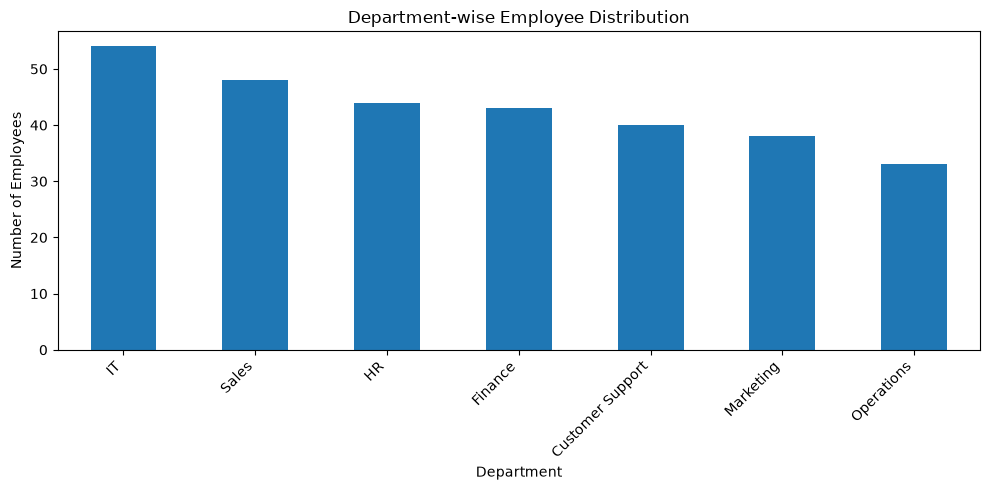

In [55]:
department_counts = (
    employee_df["Department"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
department_counts.plot(kind="bar")

plt.title("Department-wise Employee Distribution")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 13.2 Employee Salary Distribution

C:\Users\priya\AppData\Local\Temp\ipykernel_20248\3882675970.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(salary_data, vert=False)


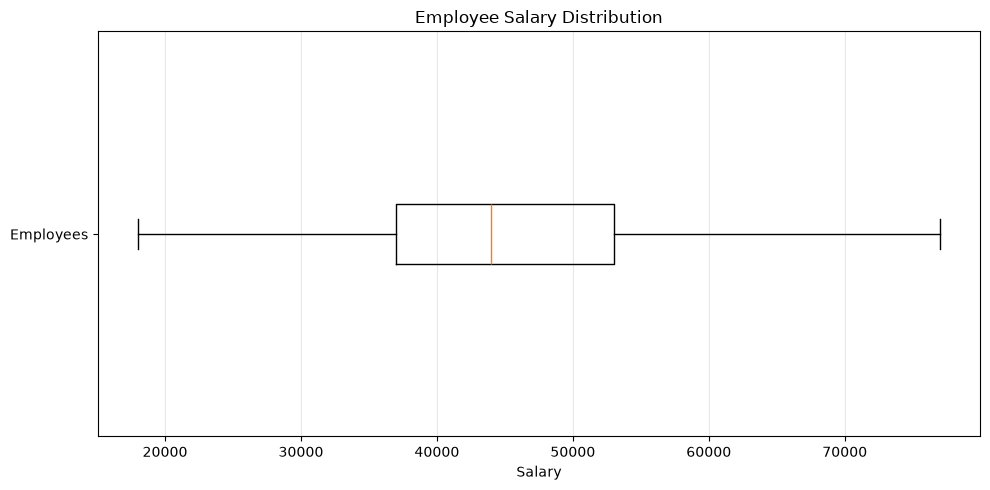

In [56]:
import matplotlib.pyplot as plt

salary_data = employee_df["Salary"].dropna()

plt.figure(figsize=(10, 5))
plt.boxplot(salary_data, vert=False)

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.yticks([1], ["Employees"])
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### 13.3 Gender-wise Workforce Distribution

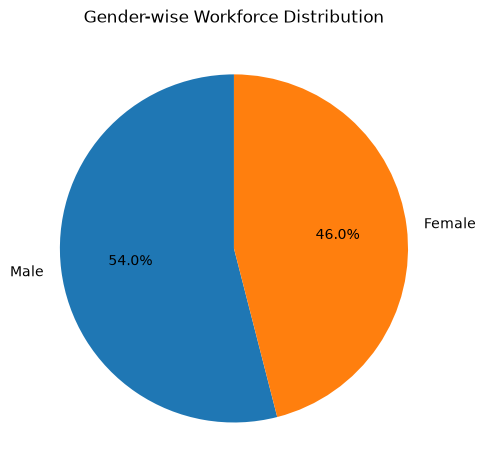

In [57]:
gender_counts = employee_df["Gender"].value_counts()

plt.figure(figsize=(5, 5))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender-wise Workforce Distribution")
plt.tight_layout()
plt.show()

#### 13.4 Monthly Attendance Trend

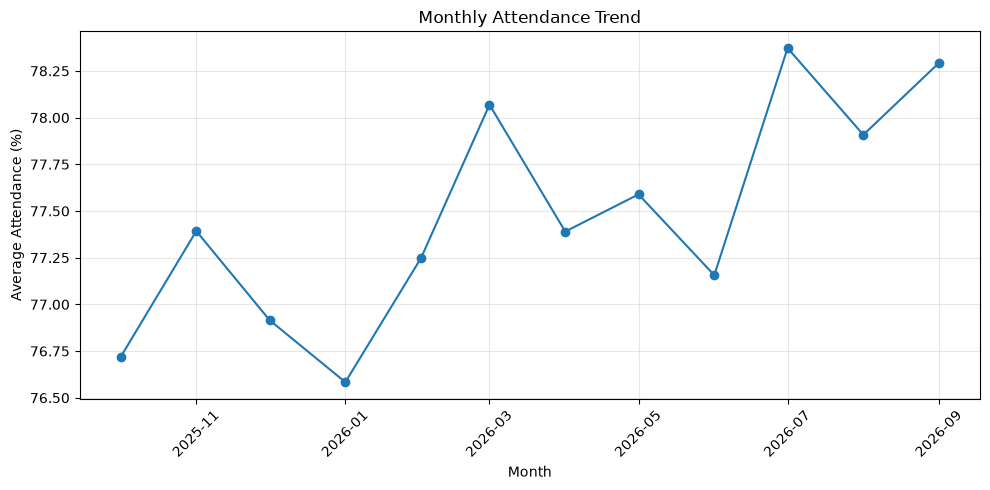

In [58]:
monthly_attendance = (
    attendance_df.groupby("Month")["Attendance_Percentage"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_attendance.index,
    monthly_attendance.values,
    marker="o"
)

plt.title("Monthly Attendance Trend")
plt.xlabel("Month")
plt.ylabel("Average Attendance (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 13.5 Recruitment Source Analysis

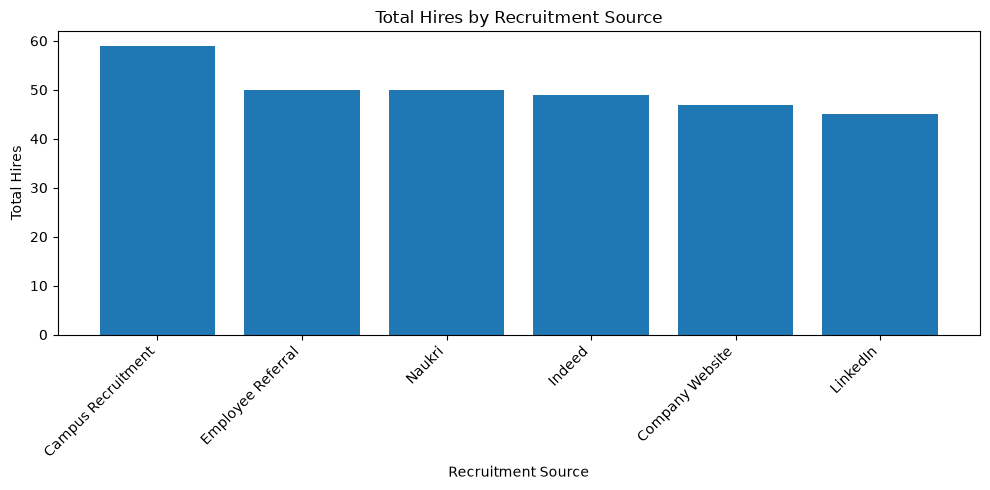

In [59]:
recruitment_sorted = recruitment_df.sort_values(
    by="Total_Hires",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    recruitment_sorted["Recruitment_Source"],
    recruitment_sorted["Total_Hires"]
)

plt.title("Total Hires by Recruitment Source")
plt.xlabel("Recruitment Source")
plt.ylabel("Total Hires")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 13.6 Employment Status Distribution

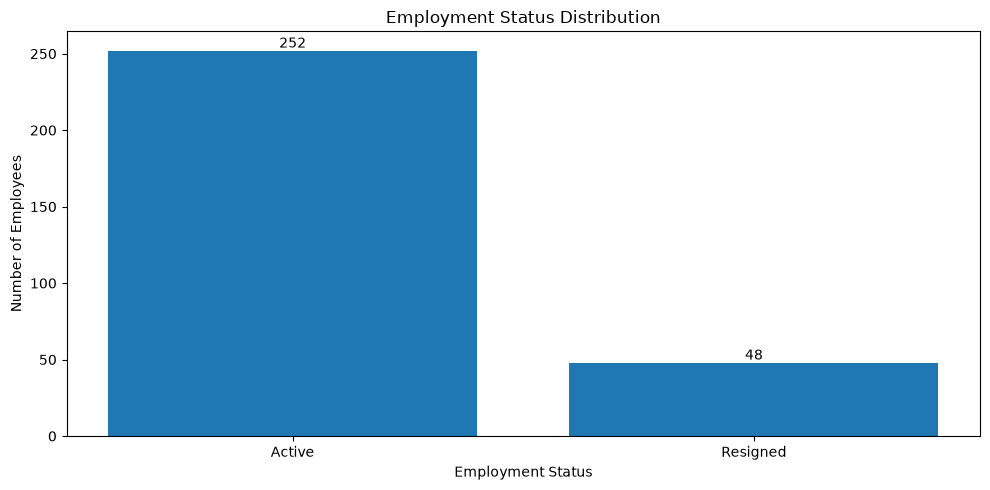

In [60]:
status_counts = employee_df["Employment_Status"].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(
    status_counts.index,
    status_counts.values
)

plt.title("Employment Status Distribution")
plt.xlabel("Employment Status")
plt.ylabel("Number of Employees")

for i, value in enumerate(status_counts.values):
    plt.text(i, value + 2, str(value), ha="center")

plt.tight_layout()
plt.show()

## 14. HR Workforce Analytics Dashboard

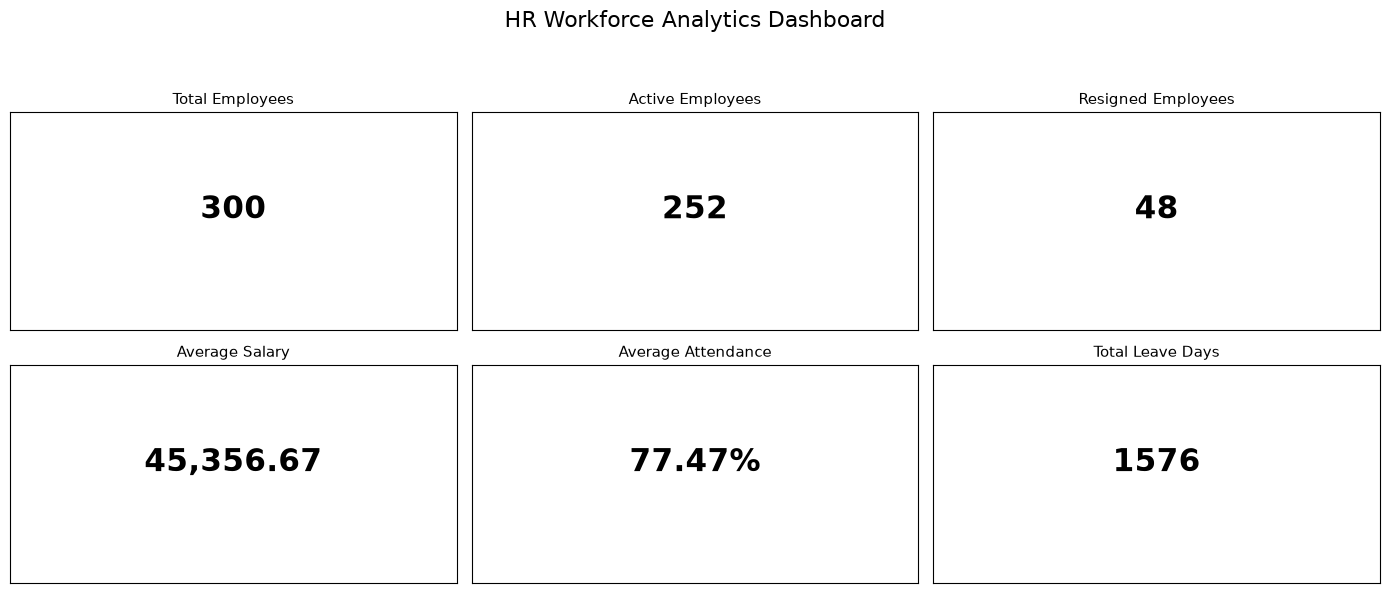

In [61]:
total_employees = len(employee_df)

active_employees = (
    employee_df["Employment_Status"]
    .astype(str).str.strip().str.lower()
    .eq("active").sum()
)

resigned_employees = (
    employee_df["Employment_Status"]
    .astype(str).str.strip().str.lower()
    .eq("resigned").sum()
)

average_salary = employee_df["Salary"].mean()
average_attendance = attendance_df["Attendance_Percentage"].mean()
total_leave_days = leave_df["Leave_Days"].sum()

kpis = [
    ("Total Employees", total_employees),
    ("Active Employees", active_employees),
    ("Resigned Employees", resigned_employees),
    ("Average Salary", f"{average_salary:,.2f}"),
    ("Average Attendance", f"{average_attendance:.2f}%"),
    ("Total Leave Days", total_leave_days)
]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
fig.suptitle("HR Workforce Analytics Dashboard", fontsize=16)

for ax, (title, value) in zip(axes.flat, kpis):
    ax.text(
        0.5, 0.55, str(value),
        ha="center", va="center",
        fontsize=22, fontweight="bold"
    )
    ax.set_title(title, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(True)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

## 15. Final Business Insights and Recommendations

### 15.1. Workforce Overview

In [62]:
total_employees = len(employee_df)

status = (
    employee_df["Employment_Status"]
    .astype(str).str.strip().str.lower()
)

active_count = status.eq("active").sum()
resigned_count = status.eq("resigned").sum()

resigned_percentage = (
    resigned_count / total_employees * 100
    if total_employees else 0
)

### 15.2. Department Analysis

In [63]:
department_counts = employee_df["Department"].value_counts()

largest_department = (
    department_counts.idxmax() if not department_counts.empty else "N/A"
)
largest_department_count = (
    department_counts.max() if not department_counts.empty else 0
)

smallest_department = (
    department_counts.idxmin() if not department_counts.empty else "N/A"
)
smallest_department_count = (
    department_counts.min() if not department_counts.empty else 0
)

### 15.3. Salary Analysis

In [64]:
average_salary = employee_df["Salary"].mean()
median_salary = employee_df["Salary"].median()
highest_salary = employee_df["Salary"].max()
lowest_salary = employee_df["Salary"].min()

### 15.4. Attendance Analysis

In [65]:
average_attendance = attendance_df["Attendance_Percentage"].mean()

monthly_attendance = (
    attendance_df.groupby("Month")["Attendance_Percentage"]
    .mean()
)

best_attendance_month = (
    monthly_attendance.idxmax() if not monthly_attendance.empty else "N/A"
)
best_attendance_value = (
    monthly_attendance.max() if not monthly_attendance.empty else 0
)

lowest_attendance_month = (
    monthly_attendance.idxmin() if not monthly_attendance.empty else "N/A"
)
lowest_attendance_value = (
    monthly_attendance.min() if not monthly_attendance.empty else 0
)

### 15.5. Leave Analysis

In [66]:
total_leave_records = len(leave_df)
total_leave_days = leave_df["Leave_Days"].sum()

leave_status = (
    leave_df["Status"].astype(str).str.strip().str.lower()
)

pending_leaves = leave_status.eq("pending").sum()
approved_leaves = leave_status.eq("approved").sum()
rejected_leaves = leave_status.eq("rejected").sum()

### 15.6. Recruitment Analysis

In [67]:
top_hiring_source = recruitment_df.loc[
    recruitment_df["Total_Hires"].idxmax()
] if not recruitment_df.empty else None

top_performance_source = recruitment_df.loc[
    recruitment_df["Average_Performance"].idxmax()
] if not recruitment_df.empty else None

top_salary_source = recruitment_df.loc[
    recruitment_df["Average_Salary"].idxmax()
] if not recruitment_df.empty else None

# Display Business Insights

In [68]:
print("=" * 65)
print("       FINAL HR WORKFORCE ANALYSIS: BUSINESS INSIGHTS")
print("=" * 65)

print("\n1. WORKFORCE OVERVIEW")
print("_" * 50)
print(f"Total employee records: {total_employees}")
print(f"Active employees: {active_count}")
print(f"Resigned employees: {resigned_count}")
print(f"Resigned employee proportion: {resigned_percentage:.2f}%")

print("\n2. DEPARTMENT DISTRIBUTION")
print("_" * 50)
print(
    f"Largest department: {largest_department} "
    f"({largest_department_count} employees)"
)
print(
    f"Smallest department: {smallest_department} "
    f"({smallest_department_count} employees)"
)

print("\n3. SALARY INSIGHTS")
print("_" * 50)
print(f"Average salary: {average_salary:,.2f}")
print(f"Median salary: {median_salary:,.2f}")
print(f"Highest salary: {highest_salary:,.2f}")
print(f"Lowest salary: {lowest_salary:,.2f}")

print("\n4. ATTENDANCE INSIGHTS")
print("_" * 50)
print(f"Average recorded attendance: {average_attendance:.2f}%")
print(
    f"Highest-attendance month: {best_attendance_month} "
    f"({best_attendance_value:.2f}%)"
)
print(
    f"Lowest-attendance month: {lowest_attendance_month} "
    f"({lowest_attendance_value:.2f}%)"
)

print("\n5. LEAVE MANAGEMENT")
print("_" * 50)
print(f"Total leave records: {total_leave_records}")
print(f"Total recorded leave days: {total_leave_days}")
print(f"Approved leave records: {approved_leaves}")
print(f"Pending leave records: {pending_leaves}")
print(f"Rejected leave records: {rejected_leaves}")

print("\n6. RECRUITMENT EFFECTIVENESS")
print("_" * 50)

if top_hiring_source is not None:
    print(
        f"Highest hiring volume: {top_hiring_source['Recruitment_Source']} "
        f"({top_hiring_source['Total_Hires']} hires)"
    )

if top_performance_source is not None:
    print(
        f"Highest average performance: "
        f"{top_performance_source['Recruitment_Source']} "
        f"({top_performance_source['Average_Performance']:.2f})"
    )

if top_salary_source is not None:
    print(
        f"Highest average salary: "
        f"{top_salary_source['Recruitment_Source']} "
        f"({top_salary_source['Average_Salary']:,.2f})"
    )

print("\n" + "=" * 65)
print("       BUSINESS INSIGHTS GENERATED SUCCESSFULLY")
print("=" * 65)

       FINAL HR WORKFORCE ANALYSIS: BUSINESS INSIGHTS

1. WORKFORCE OVERVIEW
__________________________________________________
Total employee records: 300
Active employees: 252
Resigned employees: 48
Resigned employee proportion: 16.00%

2. DEPARTMENT DISTRIBUTION
__________________________________________________
Largest department: IT (54 employees)
Smallest department: Operations (33 employees)

3. SALARY INSIGHTS
__________________________________________________
Average salary: 45,356.67
Median salary: 44,000.00
Highest salary: 77,000.00
Lowest salary: 18,000.00

4. ATTENDANCE INSIGHTS
__________________________________________________
Average recorded attendance: 77.47%
Highest-attendance month: 2026-07-01 00:00:00 (78.37%)
Lowest-attendance month: 2026-01-01 00:00:00 (76.58%)

5. LEAVE MANAGEMENT
__________________________________________________
Total leave records: 640
Total recorded leave days: 1576
Approved leave records: 391
Pending leave records: 119
Rejected leave record

## 16. Close MySQL Connection

In [69]:
cursor.close()
conn.close()

print("MySQL Connection Closed")
print("_" * 50)
print("\n=============== ANALYSIS COMPLETED ===============")
print("_" * 50)

MySQL Connection Closed
__________________________________________________

=============== ANALYSIS COMPLETED ===============
__________________________________________________
